# LFP and NMC cell-to-pack field packs

This notebook lists the field packs and laboratory cells and packs, loads one field pack, and plots its voltage over one cycle. It makes no diagnosis.

## 1. Released units

This step lists what `systems('cell_to_pack')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('cell_to_pack')
display(released)

,unit,kind,group,cycles,rated_ah,soh_first,soh_last,cells_in_series,efc_last,rated_kwh
0,Pack_field#1,field pack,Pack_field#1,605,302.0,0.991056,0.832087,416.0,609.846442,402.0224
1,Pack_field#2,field pack,Pack_field#2,609,302.0,0.998278,0.909416,416.0,610.266360,402.0224
2,Pack_field#3,field pack,Pack_field#3,585,302.0,0.959952,0.812894,416.0,574.338299,402.0224
3,Pack_field#4,field pack,Pack_field#4,600,302.0,0.993231,0.829854,416.0,604.970025,402.0224
4,Pack_field#5,field pack,Pack_field#5,593,302.0,1.016361,0.829828,416.0,609.661621,402.0224
...,...,...,...,...,...,...,...,...,...,...
56,PBSL1/Cell#28,laboratory cell,PBSL1,438,4.0,1.021654,0.653605,NaN,NaN,NaN
57,PBSL1/Cell#29,laboratory cell,PBSL1,496,4.0,0.910482,0.745926,NaN,NaN,NaN
58,PBSL1/Cell#30,laboratory cell,PBSL1,327,4.0,0.873128,0.627782,NaN,NaN,NaN
59,PBSL1/Pack#3,laboratory pack,PBSL1,449,4.0,0.986750,0.779250,NaN,NaN,NaN


The 16 field packs are the units. The laboratory packs and cells are held but not counted. All are read from Parquet copies made once in a throwaway environment.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
from fielddata.loaders import cell_to_pack
frame = cell_to_pack.load('Pack_field#1', columns=['time(s)', 'current(A)', 'Vpack', 'SOC'])
print(frame.shape)
display(frame.head())

(691190, 5)


,item,time(s),current(A),Vpack,SOC
0,0,0.0,-63.3,1265.013,5.1
1,0,18.0,-63.4,1269.692,5.2
2,0,36.0,-63.4,1273.881,5.4
3,0,54.0,-63.3,1277.698,5.5
4,0,72.0,-62.6,1280.857,5.6


All 604 released cycles of Pack_field#1, one row per sample, with item marking the cycle.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['current(A)', 'Vpack', 'SOC']].describe().T)

,count,mean,std,min,25%,50%,75%,max
current(A),691190.0,-46.526764,17.157433,-155.300,-49.70,-44.100,-34.200,-1.10
Vpack,691190.0,1389.082120,19.757921,1208.575,1384.42,1390.832,1402.234,1455.95
SOC,691190.0,50.236414,26.119094,0.000,27.80,50.200,72.600,100.00


These ranges are raw values as released, before any cleaning. The schema file next to the loader lists units and any sentinel codes.

## 4. A first look

This step plots one signal to show the shape of the data.

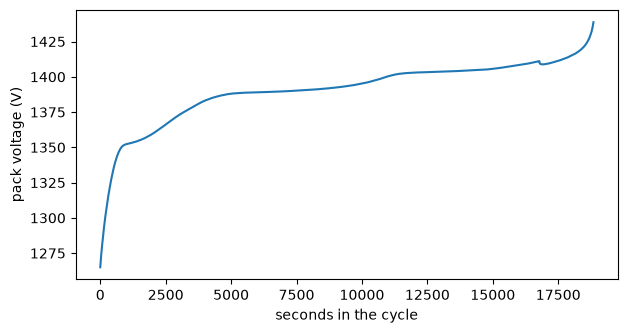

In [4]:
first = frame[frame['item'] == 0]
ax = first.plot(x='time(s)', y='Vpack', figsize=(7, 3.5), legend=False)
ax.set_xlabel('seconds in the cycle')
ax.set_ylabel('pack voltage (V)')
plt.show()

Over all cycles the pack voltage of Pack_field#1 ranges from 1,209 to 1,456 V. The plot shows the first released cycle. Values are raw, as released.